In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
import os.path as op
import glob

In [ ]:
import matplotlib as mpl
# from cycler import cycler

cmap = mpl.colormaps['hot'] # 1. Choose your colormap (e.g., 'hot', 'jet', 'turbo')
colors = cmap(np.linspace(0.0, 1.0, 7)) # 2. Extract a set of colors from it (e.g., 6 distinct colors across the map)
# plt.rcParams['axes.prop_cycle'] = cycler(color=colors) # 3. Apply it to the default line cycle
plt.rcParams['image.cmap'] = 'magma' # 4. Change the default colormap for images/scatter plots
plt.rcParams.update({
    "text.usetex": True, # Use LaTeX to write all text
    "font.family": "serif", # Use a serif font
    "font.serif": ["Computer Modern Roman"] # Specifically use the classic LaTeX font
})
plt.rcParams['image.origin'] = 'lower'

calib_dir = '/raid1/mmenessini/calibration/WFSW'
result_dir = '/raid1/mmenessini/results/WFSW'

pcoro_nir_path = '/raid1/mmenessini/results/WFSW/perfect_coro_vis/coro_psf_nir_int.fits'
pcoro_vis_path = '/raid1/mmenessini/results/WFSW/perfect_coro_vis/coro_psf_vis_int.fits'

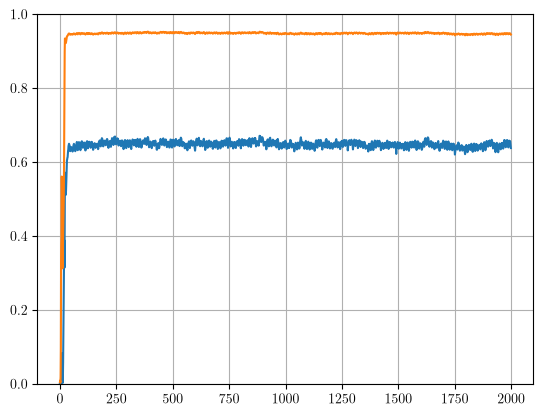

In [ ]:
result_path = sorted(glob.glob(op.join(result_dir, '20*')))[-1]
srv = fits.getdata(op.join(result_path,'sr_vis.fits'))
srn = fits.getdata(op.join(result_path,'sr_nir.fits'))

plt.figure()
plt.plot(srv)
plt.plot(srn)
plt.ylim([0,1])
plt.grid()

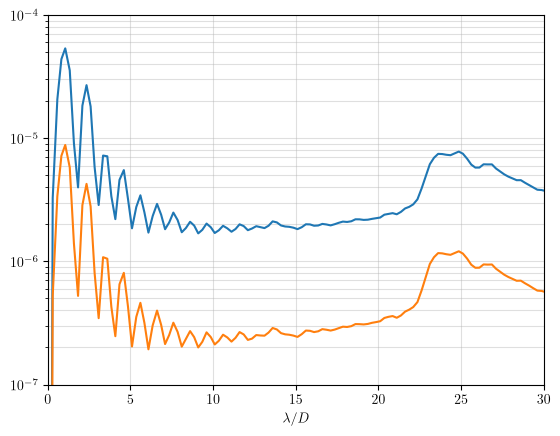

In [ ]:
radd, coro_psf_vis_int = fits.getdata(op.join(result_path,'coro_psf_vis_int.fits'))[0]
# radd, coro_psf_vis_std = fits.getdata(op.join(result_path,'coro_psf_vis_std.fits'))[0]
radd, coro_psf_nir_int = fits.getdata(op.join(result_path,'coro_psf_nir_int.fits'))[0]
# radd, coro_psf_nir_std = fits.getdata(op.join(result_path,'coro_psf_nir_std.fits'))[0]

radd, perf_coro_vis_int = fits.getdata(pcoro_vis_path)
radd, perf_coro_nir_int = fits.getdata(pcoro_nir_path)

plt.figure()
plt.semilogy(radd,coro_psf_vis_int)
plt.semilogy(radd,perf_coro_vis_int)
# plt.semilogy(radd,coro_psf_vis_std)
plt.semilogy(radd,coro_psf_nir_int)
plt.semilogy(radd,perf_coro_nir_int)
# plt.semilogy(radd,coro_psf_nir_std)
plt.ylim([1e-7,1e-4])
plt.xlim([0,30])
plt.xlabel(r'$\lambda/D$')
plt.grid(which='both',alpha=0.4)

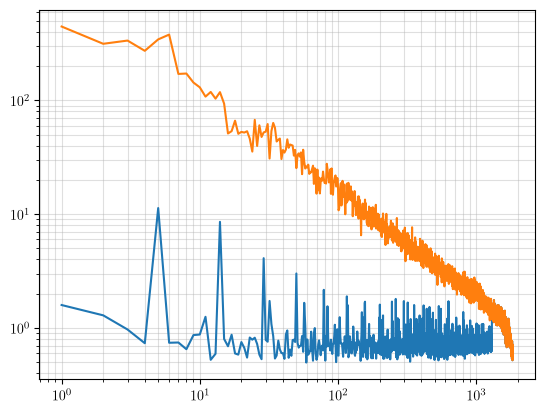

In [ ]:
# dm_modes = fits.getdata(op.join(result_path,'dm_modes.fits'))
atmo_modes = fits.getdata(op.join(result_path,'atmo_modes.fits'))
res_modes = fits.getdata(op.join(result_path,'res_modes.fits'))

N = 50

x = np.arange(res_modes.shape[1])+1
plt.figure()
# plt.loglog(x,np.sqrt(np.mean(dm_modes[N:]**2,axis=0)))
plt.loglog(x,np.sqrt(np.mean(res_modes[N:]**2,axis=0)))
plt.loglog(x,np.sqrt(np.mean(atmo_modes[N:]**2,axis=0)))
plt.grid(which='both',alpha=0.4)

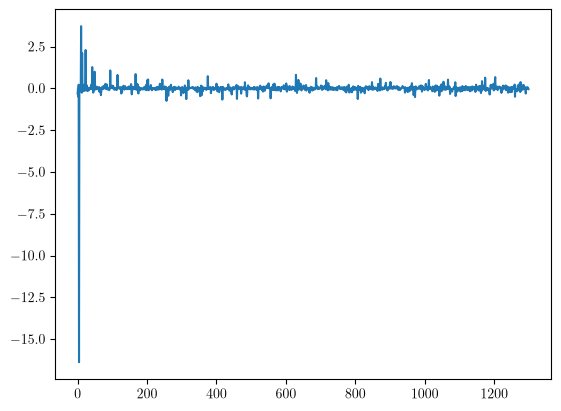

In [ ]:
kf_bias = fits.getdata(op.join(result_path,'kf_bias.fits'))

plt.figure()
# plt.plot(kf_bias[0])
# plt.plot(kf_bias[10])
# plt.plot(kf_bias[100])
plt.plot(kf_bias[1000])